# 04 · Choosing the model: which adjustments survive a test on elections they weren't fit to

**Of the three state-level adjustments I tried, only one predicted past polling misses out of sample: carrying over a share of the state's previous presidential polling miss. Scored one midterm year at a time on 344 Senate and governor races (1998–2022), it cut the average miss from 5.56 to 5.27 points; the "red-state fade" (pulling candidates who poll far above their state's lean back toward it) and a longer state polling record did nothing once tested this way. So Holdout, my midterm model, keeps the carry-over, at a weight of 0.42, and drops the rest. Those versions stay as labelled variations of Holdout, to be scored against Tuesday's results.**

Why this notebook exists: Holdout's first version (notebook 01) used a fade and a carry-over, each estimated in-sample. When Kansas, Iowa and Texas came out 12–17 points below the markets, it was tempting to swap in whichever adjustment matched the markets. That would make Holdout a copy of the markets. Instead each candidate adjustment is judged on how well it predicts elections it hasn't seen.

The full method is written up in [the methodology paper](../docs/methodology.md).

Code: `src/midterms/carryover.py` (the backtest and the variants), `src/midterms/senate.py` (the race table), [the Kansas, Iowa, Texas write-up](../docs/special-cases-ks-ia-tx.md) (the three races in depth).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from midterms import carryover as CO, senate as S

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.axisbelow": True})
BLUE, RED, INK, GREY, ORANGE = "#2a78d6", "#e34948", "#52514e", "#8a8984", "#eb6834"

## 1. What's being predicted

For every statewide race since 1998, 538's archive gives the final polling average and the result. The miss is the result minus the polls (positive means the Democrat beat the polls). Part of every race's miss is shared by the whole country that year. That national miss has flipped sign from year to year with no usable memory (notebook 01), so Holdout treats it as pure uncertainty. What a state-level adjustment can hope to predict is the rest: each race's miss **beyond** that year's national miss.

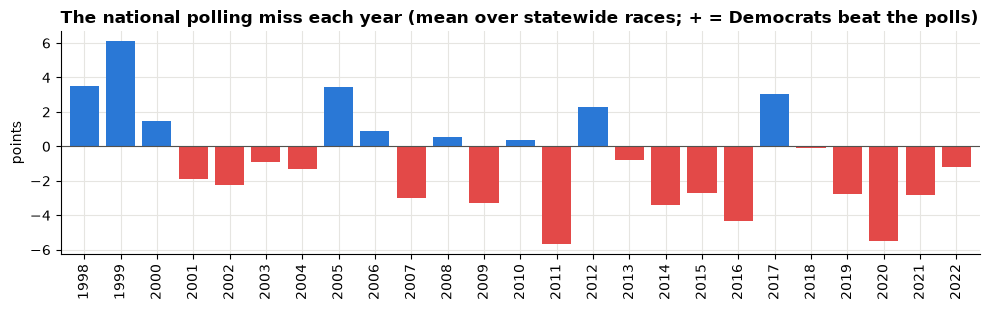

In [2]:
d = pd.read_csv(CO.ERRORS)
sw = d[d["type_simple"].isin(["Sen-G", "Gov-G", "Pres-G"])]
nat = sw.groupby("cycle")["err"].mean()
ax = nat.plot.bar(color=[BLUE if v > 0 else RED for v in nat], width=0.8, figsize=(10, 3.2))
ax.axhline(0, color=INK, lw=0.8)
ax.set(title="The national polling miss each year (mean over statewide races; + = Democrats beat the polls)", xlabel="", ylabel="points")
plt.tight_layout()

## 2. The candidates

Every predictor is built only from elections **before** the race it predicts:
- **fade**: points the Democrat polls above the state's last presidential margin (the idea: candidates far above their state's lean fall back);
- **pres**: the state's miss in the most recent earlier presidential race, beyond that year's national miss (the "2024 carry-over" for 2026);
- **hist**: the state's average miss over every statewide race in the previous 8 or 12 years, beyond each year's national miss.

Each combination is fitted on all midterm years but one and scored on the year left out.

In [3]:
t = CO.table(12)
t = t.dropna(subset=["fade", "pres", "hist"])
t = t[(t["n_hist"] >= 2) & t["midterm"]]
print(f"{len(t)} midterm Senate and governor races in {t['cycle'].nunique()} midterm years ({t['cycle'].min()}–{t['cycle'].max()})")
t[["cycle", "state", "type", "poll", "y", "fade", "pres", "hist"]].rename(columns={"y": "miss beyond national"}).head(8).round(2)

344 midterm Senate and governor races in 6 midterm years (2002–2022)


,cycle,state,type,poll,miss beyond national,fade,pres,hist
97,2002,AL,Gov-G,-2.75,4.78,4.71,9.83,3.68
99,2002,AZ,Gov-G,6.14,-2.92,12.43,3.05,-3.00
100,2002,AR,Gov-G,-8.00,4.20,-2.56,-5.40,-5.25
101,2002,CA,Gov-G,6.79,0.34,-5.01,5.23,3.24
102,2002,CO,Gov-G,-31.25,4.54,-22.89,-0.62,-2.19
103,2002,CT,Gov-G,-16.00,6.04,-33.47,5.01,0.50
104,2002,FL,Gov-G,-6.00,-4.59,-5.99,-3.28,-3.67
105,2002,GA,Gov-G,10.00,-12.91,21.69,-1.81,4.57


## 3. The scores

Root-mean-square miss on the held-out year, pooled over all six. Lower is better; "none" is the polls as they are.

In [4]:
scores = {}
for w in (8, 12):
    s, c = CO.backtest(window=w)
    scores[w] = s.set_index("spec")
tab = pd.DataFrame({"8-year record": scores[8]["rmse"], "12-year record": scores[12]["rmse"],
                    "worst single year (12y)": scores[12]["worst_cycle_rmse"]}).sort_values("12-year record").round(3)
tab

,8-year record,12-year record,worst single year (12y)
spec,,,
pres (2024-style carry-over),5.269,5.269,6.755
pres + hist,5.338,5.350,7.146
fade + pres,5.382,5.382,7.000
fade + pres + hist,5.454,5.476,7.427
hist (longer state record),5.481,5.506,7.413
none,5.555,5.555,6.545
fade,5.567,5.567,6.334
fade + hist,5.564,5.605,7.511


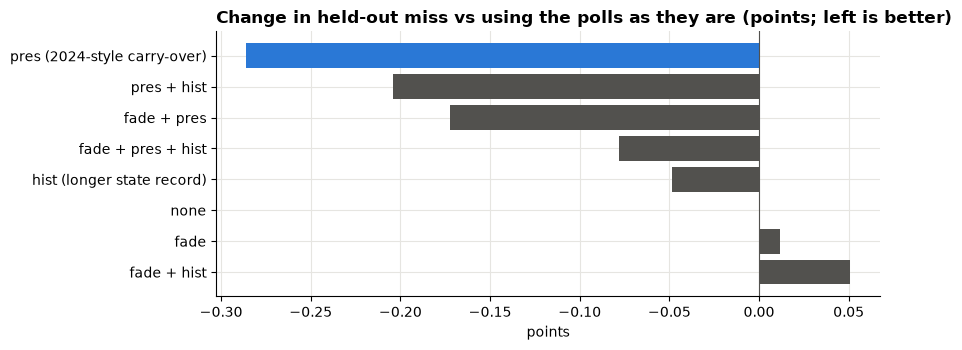

In [5]:
s12 = scores[12].sort_values("rmse")
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [BLUE if n.startswith("pres (") else GREY if n == "none" else INK for n in s12.index]
ax.barh(s12.index[::-1], (s12["rmse"] - s12.loc["none", "rmse"])[::-1], color=colors[::-1])
ax.axvline(0, color=INK, lw=0.8)
ax.set(title="Change in held-out miss vs using the polls as they are (points; left is better)", xlabel="points")
plt.tight_layout()

The presidential carry-over alone is best under both record lengths, and every combination that adds the fade or the longer record does worse than it. Adding the longer state record does help when the carry-over is absent (hist alone beats none), so the two carry overlapping information, and the more recent presidential race holds most of it.

## 4. Is it one lucky year?

The same comparison, one held-out year at a time.

In [6]:
rows = []
for c in sorted(t["cycle"].unique()):
    tr, te = t[t["cycle"] != c], t[t["cycle"] == c]
    b_p = (tr["pres"] * tr["y"]).sum() / (tr["pres"] ** 2).sum()
    b_f = (tr["fade"] * tr["y"]).sum() / (tr["fade"] ** 2).sum()
    rmse = lambda e: float(np.sqrt(np.mean(e ** 2)))
    rows.append(dict(year=c, races=len(te), none=rmse(te["y"]), carry_over=rmse(te["y"] - b_p * te["pres"]),
                     fade=rmse(te["y"] - b_f * te["fade"]), weight=b_p))
yy = pd.DataFrame(rows).set_index("year")
yy.round(2)

,races,none,carry_over,fade,weight
year,,,,,
2002,56,6.54,6.75,6.33,0.48
2006,50,4.81,5.12,5.19,0.46
2010,69,6.23,5.47,6.30,0.34
2014,51,4.99,4.86,5.23,0.45
2018,59,4.68,3.77,4.44,0.38
2022,59,5.55,5.17,5.47,0.40


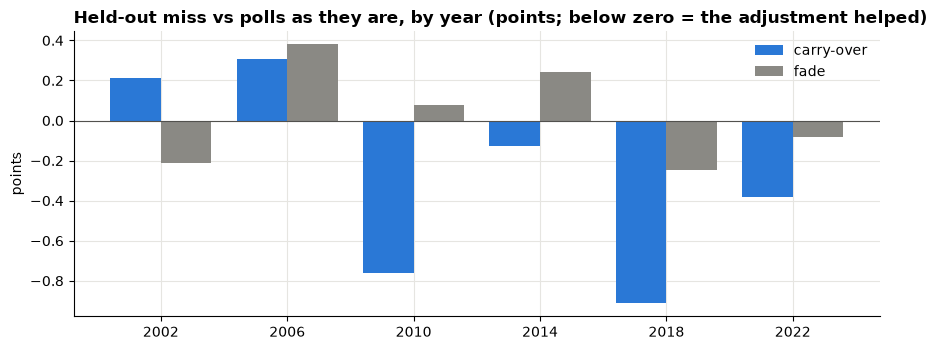

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(yy))
ax.bar(x - 0.2, yy["carry_over"] - yy["none"], width=0.4, color=BLUE, label="carry-over")
ax.bar(x + 0.2, yy["fade"] - yy["none"], width=0.4, color=GREY, label="fade")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x, yy.index)
ax.set(title="Held-out miss vs polls as they are, by year (points; below zero = the adjustment helped)", ylabel="points")
ax.legend(frameon=False)
plt.tight_layout()

The carry-over helped in each of the last four midterms (2010–2022) and hurt in 2002 and 2006; the fade helped in two years and hurt in three. The carry-over's weight, refitted without each year, stays between 0.34 and 0.48.

## 5. How certain is the weight?

Resampling whole years (races within a year share a national miss, so they aren't independent):

In [8]:
CO.bootstrap(["pres"], 12)[["mean", "5%", "50%", "95%"]].round(3)

,mean,5%,50%,95%
pres,0.408,0.22,0.421,0.557


A 90% range of roughly 0.22 to 0.56 around 0.42. Holdout's first version used 0.34, from all six presidential→midterm pairs including House races; 0.42 is fitted on exactly the target: midterm Senate and governor races.

## 6. Should a miss built from few polls count for less?

Kansas's 2024 "miss" comes from one Fort Hays State poll (three versions of the same survey), so its carry-over looks fragile. The natural fix is to discount a miss by how few polls it rests on: weight × n / (n + k). Tested the same way:

In [9]:
pres_n = sw[sw["type_simple"] == "Pres-G"].set_index(["cycle", "location"])["n"]
tt = t.copy()
tt["n_pres"] = [pres_n.get((c - (c % 4) if c % 4 else c - 4, s), np.nan) for c, s in zip(tt["cycle"], tt["state"])]


def loco(feat):
    errs = []
    for c in sorted(tt["cycle"].unique()):
        tr, te = tt[tt["cycle"] != c], tt[tt["cycle"] == c]
        b = (tr[feat] * tr["y"]).sum() / (tr[feat] ** 2).sum()
        errs.append(te["y"] - b * te[feat])
    return float(np.sqrt(np.mean(pd.concat(errs) ** 2)))


out = {"no discount": loco("pres")}
for k in (1, 3, 8):
    tt[f"k{k}"] = tt["pres"] * tt["n_pres"] / (tt["n_pres"] + k)
    out[f"discount n/(n+{k})"] = loco(f"k{k}")
print(f"{(tt['n_pres'] <= 3).sum()} of {len(tt)} races had a previous miss built from 3 or fewer polls")
pd.Series(out, name="held-out RMSE").round(3)

107 of 344 races had a previous miss built from 3 or fewer polls


no discount         5.269
discount n/(n+1)    5.271
discount n/(n+3)    5.277
discount n/(n+8)    5.289
Name: held-out RMSE, dtype: float64

Discounting makes it slightly worse. In the history, states with thin polling kept being mispolled, so a thin input still carries signal. The Kansas brief's objection stands as a judgment call, but the data don't support acting on it.

## 7. The red-state pattern the fade was meant to capture

69 races since 2000 where the Democrat (or independent) polled within 5 points or better in a state that voted Republican by 10+ for president:

mean miss -2.39; the Republican beat the polls in 71%; polled R+1 to D+4: 19 races, non-Republican won 11


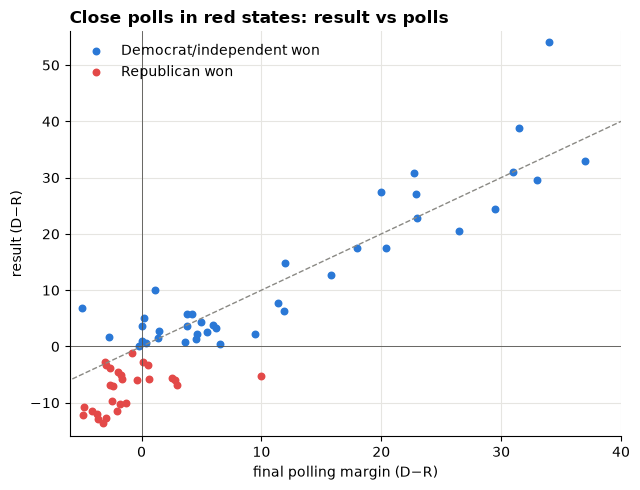

In [10]:
an = pd.read_csv("../data/history/red_state_close_polls.csv")
fig, ax = plt.subplots(figsize=(6.5, 5))
won = an["actual"] > 0
ax.scatter(an.loc[won, "poll"], an.loc[won, "actual"], color=BLUE, s=22, label="Democrat/independent won")
ax.scatter(an.loc[~won, "poll"], an.loc[~won, "actual"], color=RED, s=22, label="Republican won")
lim = (-15, 40)
ax.plot(lim, lim, color=GREY, lw=1, ls="--")
ax.axhline(0, color=INK, lw=0.6); ax.axvline(0, color=INK, lw=0.6)
ax.set(xlim=(-6, 40), ylim=(-16, 56), xlabel="final polling margin (D−R)", ylabel="result (D−R)",
       title="Close polls in red states: result vs polls")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
print(f"mean miss {an['err'].mean():+.2f}; the Republican beat the polls in {(an['err'] < 0).mean():.0%};"
      f" polled R+1 to D+4: {an['poll'].between(-1, 4).sum()} races, non-Republican won {((an['poll'].between(-1, 4)) & won).sum()}")

The pattern is real in the raw numbers (dots below the dashed line), but about half of it is the national miss in years like 2020, and the rest (about 1.3 points beyond the national miss) doesn't scale with how far above the lean a candidate polls in a way that predicts new races (section 3). Candidate quality cuts both ways: this year's three cases have a weak Republican Senate nominee on a ticket whose other Republicans poll fine, which a lean-based fade would penalise.

## 8. What each version says for 2026

Holdout and its three variations, simulated with the same error model (national SD 3.0, fat-tailed; state and race errors), against the latest snapshot.

In [11]:
df = S.races()
res = {}
for v in CO.VARIANTS:
    sim, summ = S.simulate(df.assign(_c=CO.center(df, v)), "_c", S.ErrorModel(), n=60_000, seed=0)
    res[v] = sim.set_index("state")["sim_p_d"]
    res[v]["Senate control"] = summ["p_d_control"]
v = pd.DataFrame(res).rename(columns={"robust": "main (tested)"})
v["Polymarket"] = df.set_index("state")["pm_p_d"]
focus = ["Senate control", "KS", "IA", "TX", "OH", "AK", "ME", "NC", "MI", "NE", "SC"]
(100 * v.loc[[f for f in focus if f in v.index]]).round(0)

,main (tested),first version,longer state record,no adjustments,Polymarket
state,,,,,
Senate control,73.0,68.0,77.0,78.0,NaN
KS,39.0,36.0,57.0,57.0,54.0
IA,33.0,31.0,43.0,52.0,45.0
TX,63.0,59.0,76.0,73.0,72.0
OH,74.0,70.0,66.0,74.0,70.0
AK,74.0,68.0,71.0,73.0,70.0
ME,69.0,70.0,70.0,69.0,70.0
NC,98.0,97.0,98.0,97.0,98.0
MI,81.0,80.0,83.0,80.0,78.0


The tested version of Holdout moves Senate control from 68% (first version) to 73%, about where the markets are, but still sits 9–15 points below Polymarket in Kansas, Iowa and Texas. In each, the 2024 carry-over is what separates Holdout from the markets; [the Kansas, Iowa, Texas write-up](../docs/special-cases-ks-ia-tx.md) works through the polls, money, early vote and candidate quality behind each one.

## 9. What this leaves open

- **Six midterm years is a small sample.** The carry-over's gain is about 5% of the error, and it lost in two of six years.
- **Split Ticket may already include something like these adjustments.** Averaging it in and then applying the carry-over could partly double-count.
- **The 2024 inputs vary in quality.** Kansas rests on one poll. Iowa and Texas use published averages, and Iowa's includes Selzer's final-week outlier.
- **Tuesday scores it.** Every version is on the [map page](https://axel5o5.github.io/midterms-2026/); after the results, each is scored race by race against the markets and the other forecasters.